In [2]:

# RETAIL SALES ANALYSIS
# Python Data Analytics Project

"""
Objective:
Analyze retail sales data to understand:
1. Overall business performance
2. Sales and profit trends
3. Category and sub-category performance
4. Regional performance
5. Customer purchasing behavior
6. Impact of discounts on profitability

Tools: Pandas, NumPy, Matplotlib, Seaborn
"""
print("Retail Sales Analysis Project")
print("Exploring business performance through data!")


Retail Sales Analysis Project
Exploring business performance through data!


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name, encoding="latin1")

print("Dataset uploaded successfully!")


Saving archive (10).zip to archive (10) (1).zip
Dataset uploaded successfully!


In [5]:

print("First 5 rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)


First 5 rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   objec

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1237,9/5/2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:

print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Data types:")
display(df.dtypes)


Missing values:


,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


Duplicate rows: 0
Data types:


,0
Row ID,int64
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


In [7]:

# Keep a copy of the original dataset
df = df.copy()

# Remove duplicate records
df = df.drop_duplicates()

# Convert date columns
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

# Remove rows with invalid essential values
df = df.dropna(subset=["Order Date", "Sales", "Profit"])

# Standardize text columns
text_columns = ["Category", "Sub-Category", "Region", "Segment"]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Create useful time-based columns
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)

print("Data cleaning completed!")
print("Cleaned dataset shape:", df.shape)

display(df.head())


Data cleaning completed!
Cleaned dataset shape: (9994, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Year-Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,2016-06
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,2015-10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,2015-10


In [8]:

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["Product ID"].nunique()

# Calculate average order value correctly:
order_sales = df.groupby("Order ID")["Sales"].sum()
average_order_value = order_sales.mean()

profit_margin = (total_profit / total_sales) * 100

print("========== BUSINESS PERFORMANCE ==========")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")


========== BUSINESS PERFORMANCE ==========
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Unique Products: 1,862
Average Order Value: $458.61
Profit Margin: 12.47%


,Sales
Category,
Technology,836154.0330
Furniture,741999.7953
Office Supplies,719047.0320


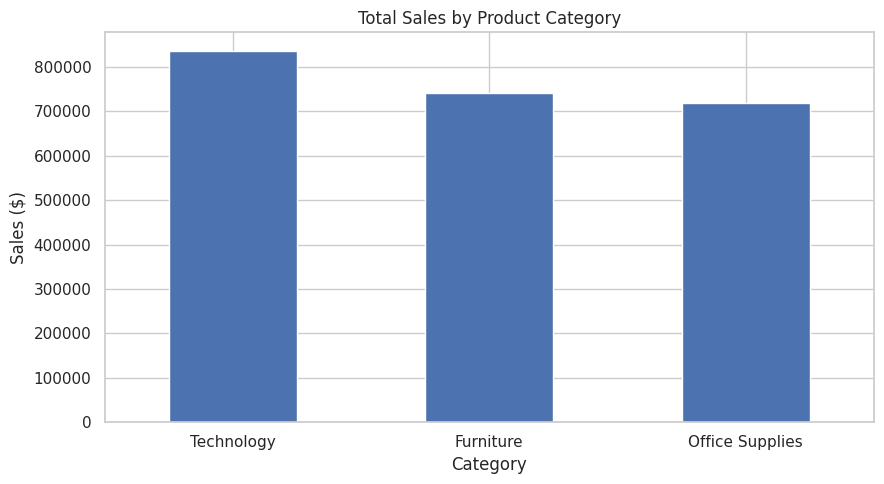

In [9]:

category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(category_sales)

category_sales.plot(kind="bar", figsize=(9, 5))

plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


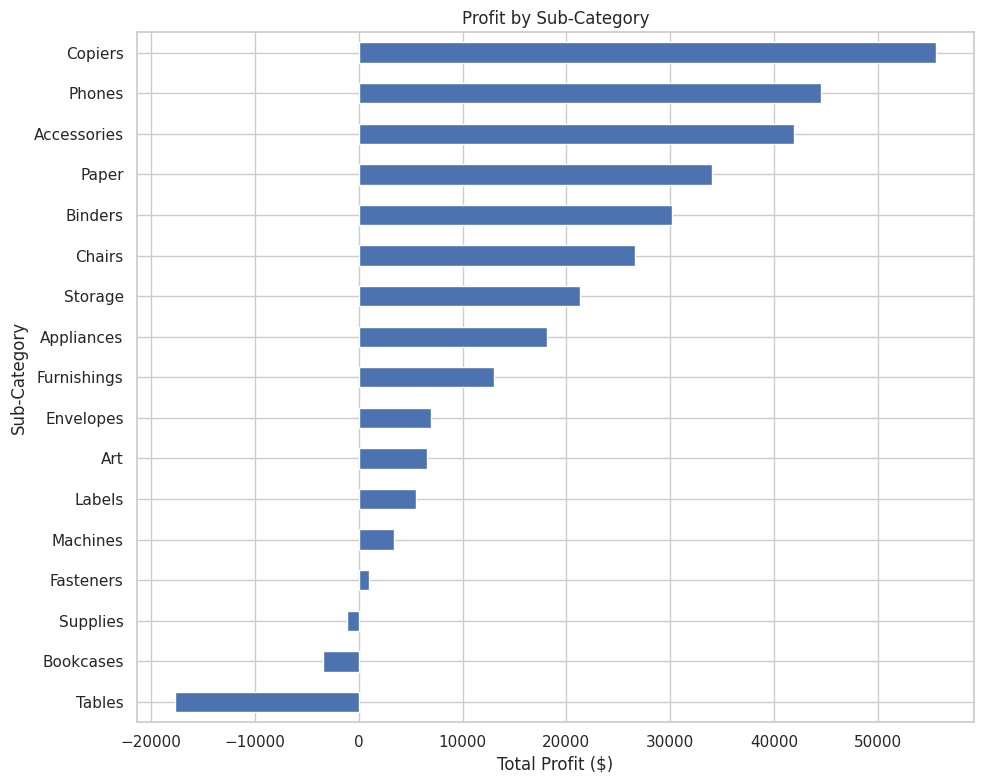

Most profitable sub-category:
Copiers

Least profitable sub-category:
Tables


In [10]:

subcategory_profit = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values()
)

subcategory_profit.plot(kind="barh", figsize=(10, 8))

plt.title("Profit by Sub-Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

print("Most profitable sub-category:")
print(subcategory_profit.idxmax())

print("\nLeast profitable sub-category:")
print(subcategory_profit.idxmin())


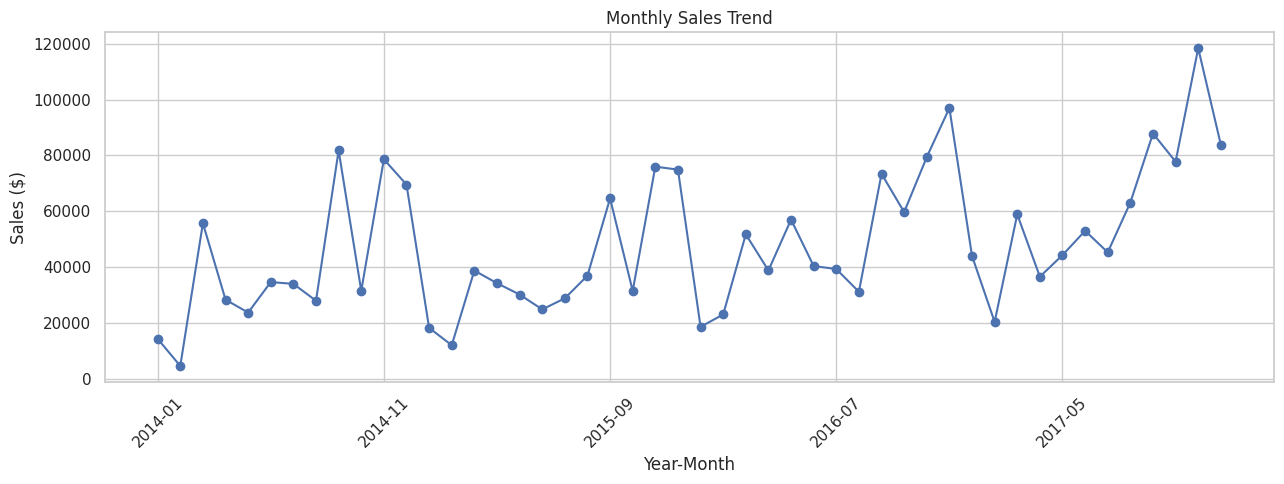

Highest sales month: 2017-11
Lowest sales month: 2014-02


In [11]:

monthly_sales = (
    df.groupby("Year-Month")["Sales"]
    .sum()
    .sort_index()
)

monthly_sales.plot(kind="line", marker="o", figsize=(13, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Highest sales month:", monthly_sales.idxmax())
print("Lowest sales month:", monthly_sales.idxmin())


,Total_Sales,Total_Profit,Orders
Region,,,
West,725457.8245,108418.4489,1611
East,678781.2400,91522.7800,1401
Central,501239.8908,39706.3625,1175
South,391721.9050,46749.4303,822


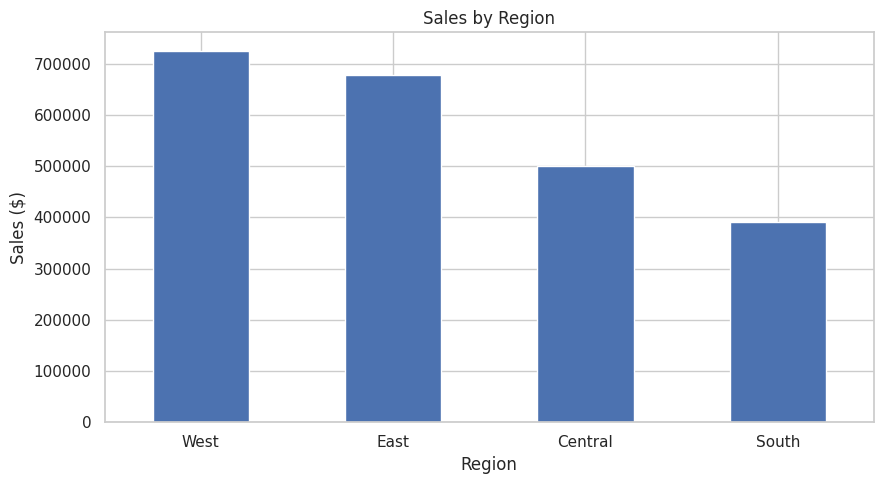

In [12]:

regional_performance = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(regional_performance)

regional_performance["Total_Sales"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Top 10 customers by sales:


,,Total_Sales,Total_Profit,Total_Orders
Customer ID,Customer Name,,,
SM-20320,Sean Miller,25043.050,-1980.7393,5
TC-20980,Tamara Chand,19052.218,8981.3239,5
RB-19360,Raymond Buch,15117.339,6976.0959,6
TA-21385,Tom Ashbrook,14595.620,4703.7883,4
AB-10105,Adrian Barton,14473.571,5444.8055,10
KL-16645,Ken Lonsdale,14175.229,806.8550,12
SC-20095,Sanjit Chand,14142.334,5757.4119,9
HL-15040,Hunter Lopez,12873.298,5622.4292,6
SE-20110,Sanjit Engle,12209.438,2650.6769,11


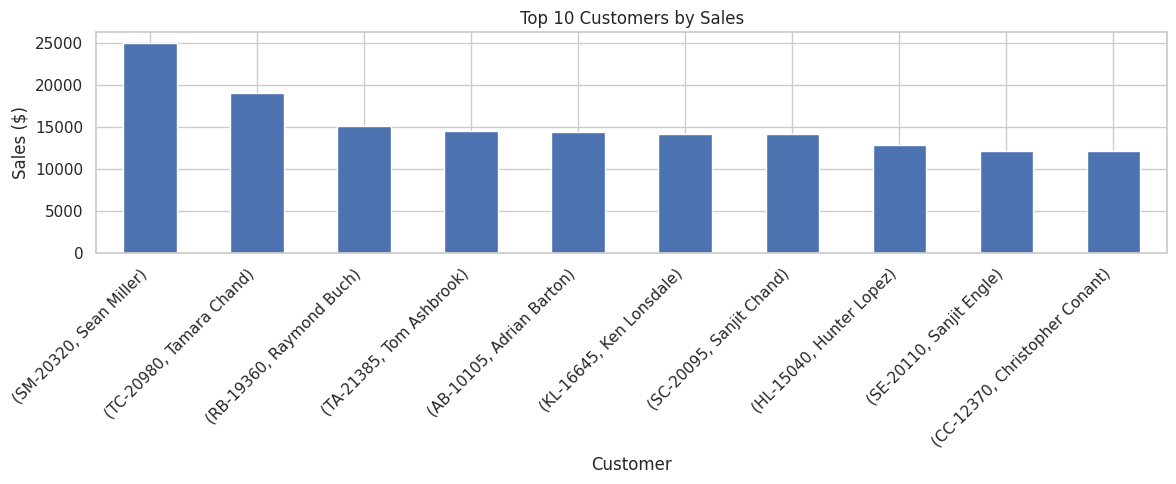

In [13]:

customer_analysis = (
    df.groupby(["Customer ID", "Customer Name"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

print("Top 10 customers by sales:")
display(customer_analysis.head(10))

customer_analysis.head(10)["Total_Sales"].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Customer")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


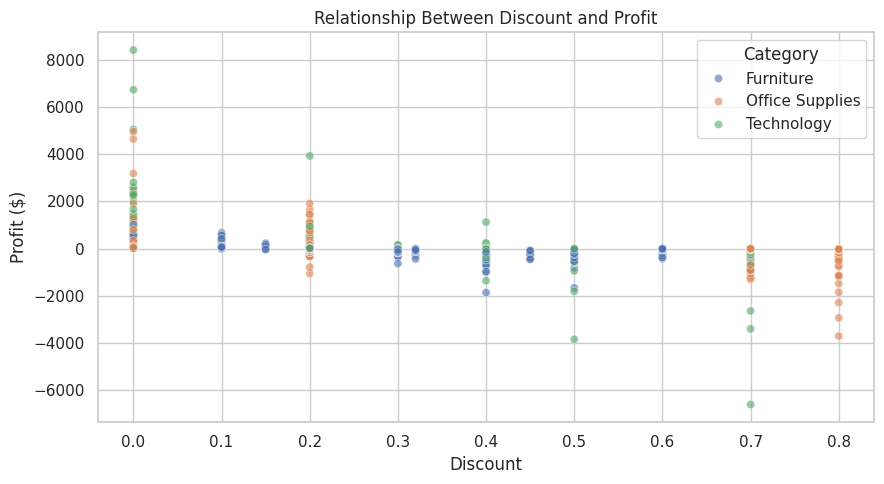

,Average_Profit,Total_Sales,Transactions
Discount,,,
0.00,66.900292,1.087908e+06,4798
0.10,96.055074,5.436935e+04,94
0.15,27.288298,2.755852e+04,52
0.20,24.702572,7.645944e+05,3657
0.30,-45.679636,1.032267e+05,227
0.32,-88.560656,1.449346e+04,27
0.40,-111.927429,1.164178e+05,206
0.45,-226.646464,5.484974e+03,11
0.50,-310.703456,5.891854e+04,66


In [14]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.6
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()

discount_analysis = (
    df.groupby("Discount")
    .agg(
        Average_Profit=("Profit", "mean"),
        Total_Sales=("Sales", "sum"),
        Transactions=("Order ID", "count")
    )
)

display(discount_analysis)


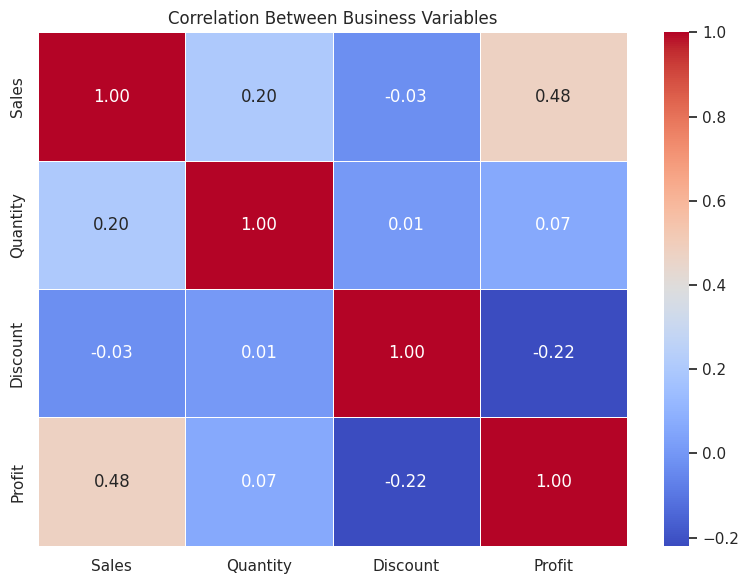

In [15]:

numeric_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Business Variables")
plt.tight_layout()
plt.show()


In [16]:

best_category = df.groupby("Category")["Sales"].sum().idxmax()
best_region = df.groupby("Region")["Sales"].sum().idxmax()
best_subcategory = df.groupby("Sub-Category")["Profit"].sum().idxmax()
worst_subcategory = df.groupby("Sub-Category")["Profit"].sum().idxmin()

print("========== BUSINESS INSIGHTS ==========")

print(f"1. Highest revenue category: {best_category}")
print(f"2. Highest revenue region: {best_region}")
print(f"3. Most profitable sub-category: {best_subcategory}")
print(f"4. Lowest profit sub-category: {worst_subcategory}")

print(f"5. Overall profit margin: {profit_margin:.2f}%")
print(f"6. Average order value: ${average_order_value:,.2f}")

if profit_margin > 0:
    print("7. Overall business is profitable.")
else:
    print("7. Overall business is operating at a loss.")


========== BUSINESS INSIGHTS ==========
1. Highest revenue category: Technology
2. Highest revenue region: West
3. Most profitable sub-category: Copiers
4. Lowest profit sub-category: Tables
5. Overall profit margin: 12.47%
6. Average order value: $458.61
7. Overall business is profitable.


In [17]:

df.to_csv("cleaned_superstore_data.csv", index=False)

regional_performance.to_csv("regional_performance.csv")
customer_analysis.to_csv("customer_analysis.csv")

print("Analysis files exported successfully!")


Analysis files exported successfully!


In [18]:

from google.colab import files

files.download("cleaned_superstore_data.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>